# Summary of Project

Our client is a rental agency, assumed to be based in Metro Melbourne, that wants to grow across Victoria. We were asked to advise on three decisions:

1. **Where to invest and expand.** The agency should move into suburbs where rents are forecast to grow, since higher rents mean higher commission. The rental market must also be large enough to give a steady number of leases each year, and the suburb should be liveable and affordable, so tenants stay longer (no need to vacate frequently) and properties lease quickly.
2. **Which properties to acquire, and on what terms.** The agency should estimate the weekly rent of each property, then use that estimate to decide which properties to pursue and what management fee to offer landlords.
3. **Which upgrades to recommend to landlords.** Changeable features of a property, such as solar panels, may raise its rent, which increases the landlord's income and the agency's management fee.

To support these decisions, we answered three questions for Victoria:

1. Which internal and external features have the biggest effect on rental price?
2. Which 10 suburbs have the highest forecast rental growth over the next five years?
3. Which suburbs are the most liveable and affordable?

The sections below follow the order of our presentation: data preparation, rent forecasting (Question 2), liveability and affordability (Question 3), rent drivers and pricing (Question 1), and finally our recommendation. An interactive dashboard with suburb rent forecasts to 2031 and a property rent estimator is available at https://ads-a2-dashboard-web-nu.vercel.app/rent-forecast/.

# Key Findings

1. **Rent drivers (Question 1):** Property size dominates, led by bedrooms and then bathrooms, followed by area income and distance to the beach and the CBD. Our pricing model estimates weekly rent with an average error of $58.20 (8.8%).
2. **Highest growth (Question 2):** Keilor (72.6%), Morwell (69.6%) and Moe-Newborough (63.2%) lead the forecast five-year rent growth, and nine of the top ten suburbs are regional centres.
3. **Liveability and affordability (Question 3):** Liveability is highest in inner Melbourne and low across regional Victoria. Elsternwick, Travancore and Brighton are the most liveable suburbs, and Fairfield-Alphington, West Brunswick and Ballarat are the most affordable. Among the regional growth candidates, Greater Bendigo is the most liveable, and affordability does not rule out any candidate.
4. **Recommendation:** Expand into Greater Bendigo, price properties with our estimation tool to set management fees, and recommend solar upgrades to landlords.

# Data Cleaning

We were provided with a dataset of over 12,000 rental listings across Victoria, originally scraped from Domain. The raw data was inconsistent and was cleaned as outlined below. Clean listings mean more reliable rent estimates, which allows the agency to price properties and set management fee offers with confidence.

1. **Core fields:** Fitted the data to a defined schema and removed listings that are not liveable rentals (e.g. vacant land, car spaces) or have an implausible weekly rent. Missing bedroom, bathroom and car space counts were set to 0, unless the count was missed at random when the data was scraped (filled in manually).
2. **Property features:** Free text descriptions were standardised and merged into 52 yes or no features (for example, dishwasher or split system heating), plus a numeric energy rating. These show which property features tenants pay more for.

Challenges

* Over 500 inconsistent feature descriptions, many of which were spelling variants of the same feature
* Separating genuinely missing values from values the scraper could not capture

Limitations

* Features in fewer than 100 listings were dropped, so rare amenities are not represented

Assumptions

* A missing bedroom or car space count in the listing was sometimes assumed to mean that the property has none
* A feature not mentioned in a listing is absent from the property
* Rents outside $203 to $10,000 per week are errors rather than genuine listings

# Data Gathering and Merging

Beyond the provided listings, we gathered external data on income, rent history, public transport, amenities and crime, so that each suburb can be judged on what tenants care about.

* **ABS:** population and income by Statistical Area 2 (SA2).
* **Department of Families, Fairness and Housing (DFFH):** quarterly median rent by suburb, used for growth forecasting and affordability.
* **Public Transport Victoria:** locations of bus stops and train stations.
* **Victorian Government open data:** school locations, parks and conservation reserves, sport and recreation facilities, and crime statistics by Local Government Area (LGA).
* **OpenStreetMap and OpenRouteService (ORS):** amenities such as hospitals, doctors, parks and beaches, and the road distance from each property to them (retrieved using API).

Security: API keys and non-public data are managed via local .env files and excluded from GitHub via .gitignore to prevent credential exposure.

Challenges

* Different datasets used different geographic levels (SA2, LGA, suburb), so merging them required care
* Finding true road distances without making an API request for every property and amenity

Limitations

* Crime rates are only available at LGA level, so all suburbs in the same LGA share one value

Assumptions

* The external features chosen are appropriate and sufficient for rental price prediction

# Time Series Modelling

We forecast median rent for each of the 146 suburbs and suburb groups in the DFFH quarterly rental dataset, which runs from 2000 to September 2025. The forecasts let us estimate rental growth through to September 2031.

This matters because, as a rental agency, we want to invest and expand where rents are projected to grow, since higher rents mean higher commissions.

A separate ARIMA model was built for each suburb:

1. A log transformation was applied to rent, as prices grow multiplicatively.
2. Augmented Dickey-Fuller (ADF) tests were run to check for stationarity, using both a linear trend and a trend break specification.
3. The series was differenced as many times as required to become stationary.
4. The fitted models were used to forecast median rent to September 2031.

To evaluate the models, we trained on data up to 2019 and compared six years of forecasts against actual rents up to 2025. The median gap between forecast and actual rents was about 8.3%.

Challenges

* Choosing an appropriate stationarity treatment and model order for 146 different series

Limitations

* The six-year evaluation window includes COVID-19, which is a major limitation for our forecast evaluation. Prediction intervals were unreliable, and accuracy was lower for some suburbs because rents fell sharply in 2020 while our forecasts expected steady growth. Under normal circumstances, we would expect the metrics to be better.
* Data for 2026 was not available, so our 5-year growth figures were calculated from a forecasted 2026 value

Assumptions

* Historical trends in each suburb are a reasonable guide to future rent growth
* The forecasted 2026 values are reasonably accurate

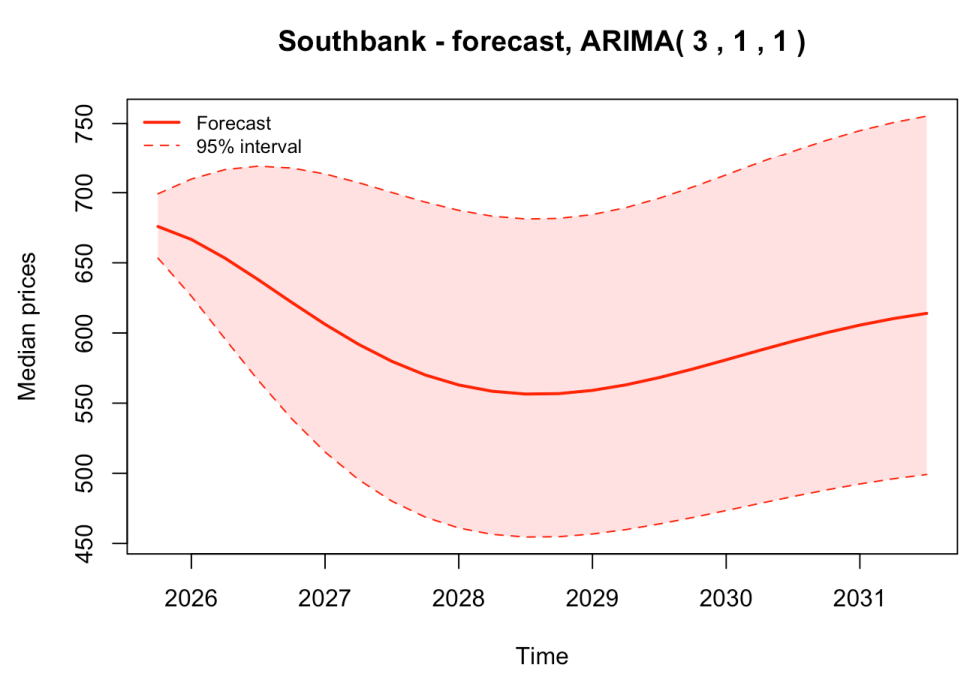

The above image is the 6-year ahead projection from 2025 September for Southbank. Similar projections for median weekly rent till 2031 September exist for various Victorian suburbs.

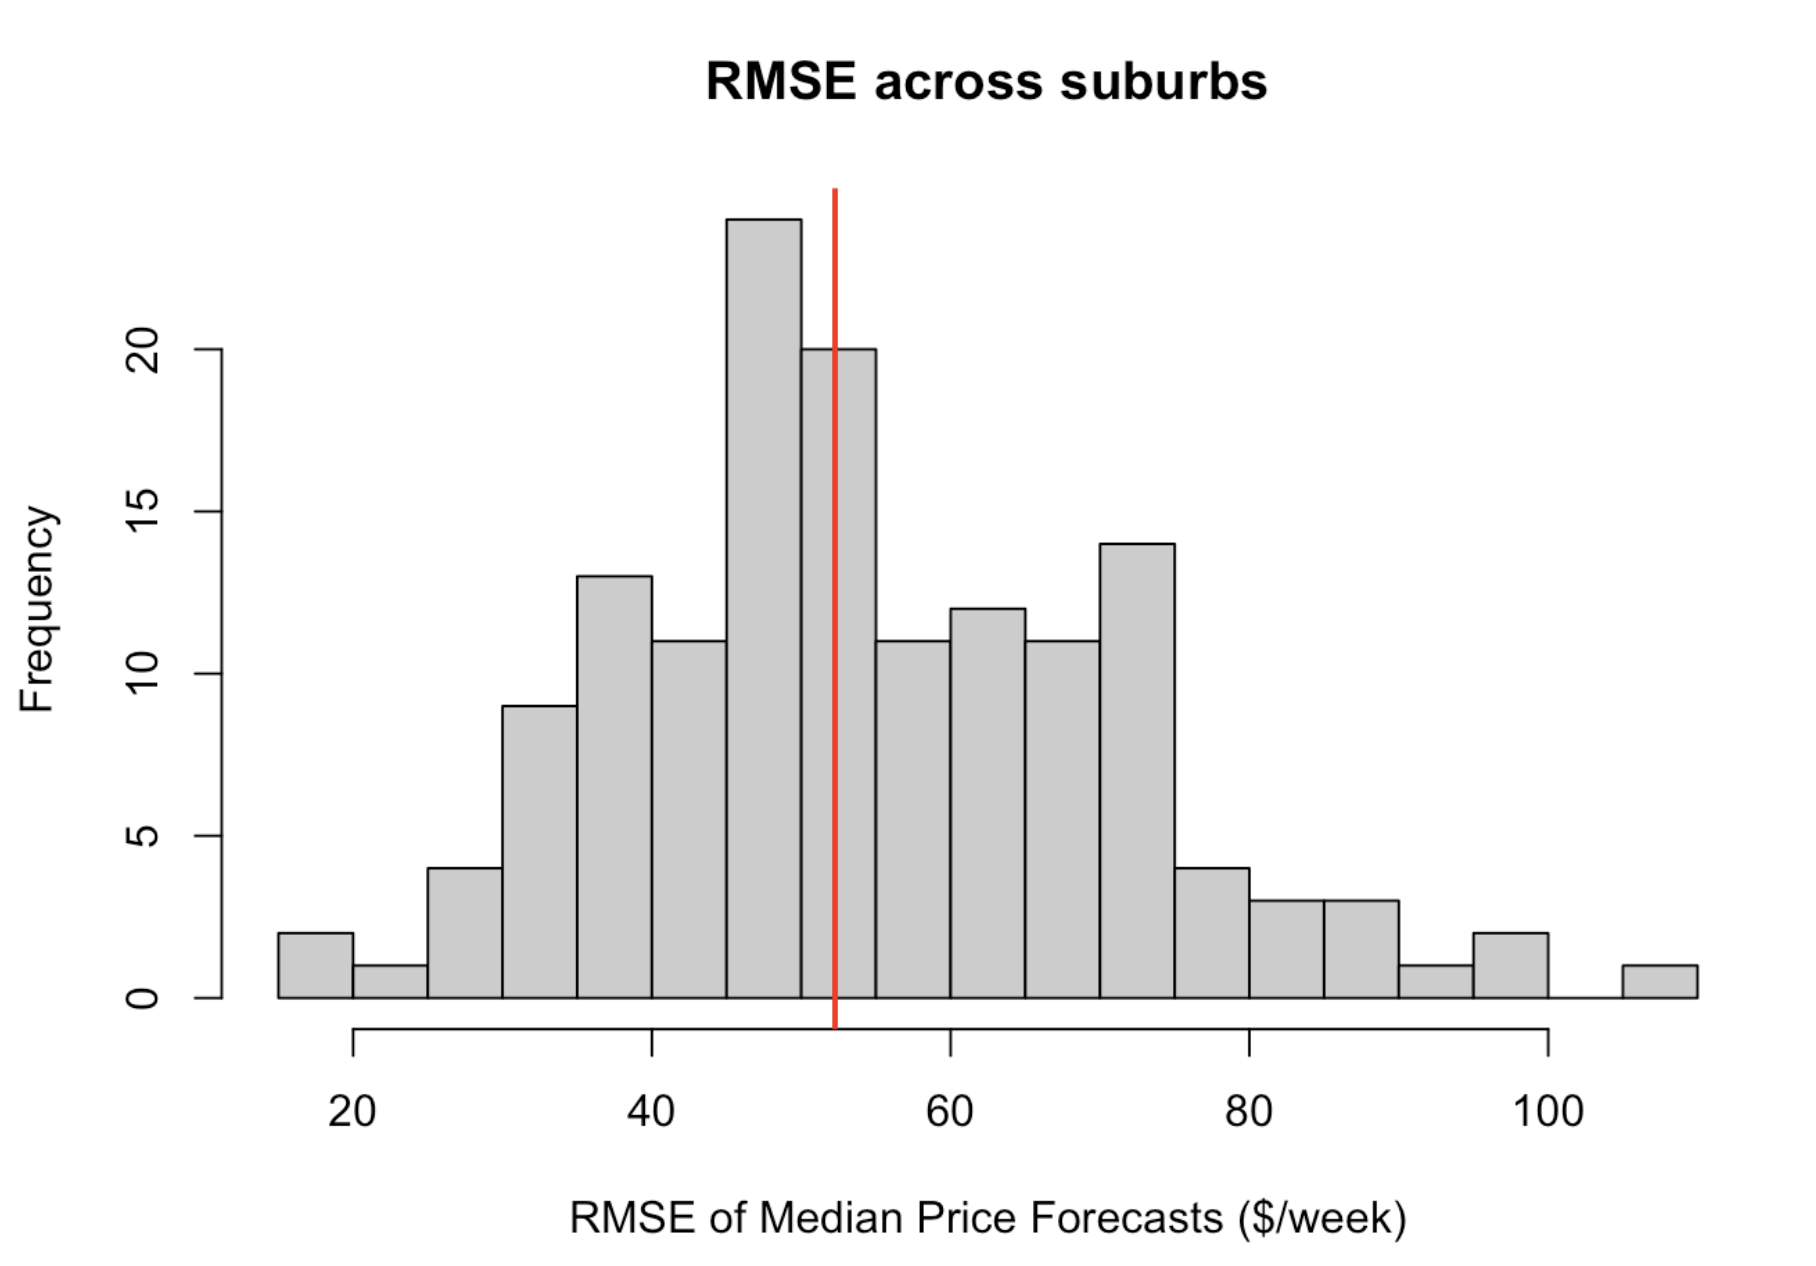

The histogram shows the root mean squared error (RMSE) of the six-year median rent forecasts for each of the 146 suburbs, in dollars per week. The red line marks the median RMSE of about $52 a week. Because rents differ across suburbs, the median percentage gap of about 8.3% is the more comparable measure of accuracy.

## Top 10 Suburbs by Forecast Rental Growth

| Rank | Suburb | Sep 2026 | Sep 2031 | Growth |
|:----:|:-------|---------:|---------:|-------:|
| 1 | Keilor | $725 | $1,251 | +72.6% |
| 2 | Morwell | $422 | $717 | +69.6% |
| 3 | Moe-Newborough | $430 | $702 | +63.2% |
| 4 | Golden Square-Kangaroo Flat | $520 | $839 | +61.4% |
| 5 | Shepparton | $506 | $804 | +59.0% |
| 6 | Swan Hill | $464 | $728 | +57.0% |
| 7 | Warragul | $602 | $935 | +55.4% |
| 8 | Wodonga | $542 | $818 | +51.1% |
| 9 | Mildura | $488 | $731 | +49.9% |
| 10 | North Bendigo | $521 | $778 | +49.3% |

Nine of the ten suburbs are regional centres, and Keilor is the only Melbourne suburb on the list.

Growth alone is not enough, because commission depends on volume as well as rent. Many of these suburbs are small rental markets, so a high growth rate applies to few leases and would not give the agency a steady business. Keilor, for example, had only 43 leases in the last year. To judge whether an office would be commercially viable, we compared growth with the number of leases in the last 12 months, used as a proxy for market size.

| Suburb | Forecast growth | Leases (last 12 months) | Outcome |
|:-------|----------------:|------------------------:|:--------|
| Keilor | 72.6% | 43 | Too small |
| Morwell | 69.6% | 557 | Smaller market |
| Moe-Newborough | 63.2% | 431 | Smaller market |
| Greater Bendigo (Golden Square-Kangaroo Flat and North Bendigo) | 61.4% and 49.3% | 1,376 | Shortlisted |
| Shepparton | 59.0% | 1,522 | Shortlisted |
| Swan Hill | 57.0% | 250 | Smaller market |
| Warragul | 55.4% | 524 | Smaller market |
| Wodonga | 51.1% | 1,166 | Smaller market |
| Mildura | 49.9% | 1,344 | Shortlisted |

North Bendigo and Golden Square-Kangaroo Flat are close together and both in the top 10, so the agency could operate across both as a single market. Among the high growth suburbs, these three areas have the largest rental markets, so they pair high forecast growth with enough volume to support an office. We treat them as the strongest expansion candidates.

# Liveability

A suburb is more liveable when its rental properties are closer to everyday amenities and its crime rate is lower. We scored each suburb on five categories, with weights adapted from the Economist Intelligence Unit Global Liveability Index:

| Category | Weight | Features (weight) |
|:---------|-------:|:------------------|
| Stability | 25% | Crime rate (25%) |
| Culture and environment | 25% | Sports and recreation (7.5%), local park (7.5%), shopping centre (10%) |
| Healthcare | 20% | Hospital (13%), doctor practice (7%) |
| Infrastructure | 20% | CBD (5%), bus stop (5%), train station (10%) |
| Education | 10% | Primary school (5%), secondary school (5%) |

Features are the distance to the nearest facility, except for crime rate. As a rental agency, we want to operate in areas where tenants stay longer. Satisfied tenants vacate less often, which reduces vacancy time and the number of Saturday inspections.

For every feature, a smaller value is better (a shorter distance or a lower crime rate), so the score was built as follows:

1. Duplicate properties at the same coordinates were removed.
2. Suburbs with fewer than 5 properties were dropped.
3. The median of each feature was taken for each suburb.
4. Each feature was standardised so that no feature dominates because of its scale.
5. Features were combined using a weighted sum, with the weights above.
6. The direction was flipped and the result rescaled so that a higher score means a more liveable suburb.

Challenges

* Adapting a city level index to a suburb level metric

Limitations

* Property data was limited, so 270 suburbs with fewer than 5 properties were dropped
* Scores are a snapshot and will change as suburbs develop

Assumptions

* The Global Liveability Index is an appropriate framework for our category weights
* Nearby suburbs can approximate a suburb's liveability decently, since liveability doesn't change significantly across suburb boundaries.

![Liveability percentile by suburb across Victoria](Figures/liveability_map.png)

Liveability, as expected, is highest in the inner suburbs (specifically eastern suburbs) of Melbourne. It is usually low in regional Victoria, which is also where higher growth in weekly rent is expected.

## Liveability of Candidate Regional Areas

| Suburb | Liveability (percentile) |
|:-------|-------------------------:|
| Bendigo | 64.97% |
| North Bendigo | 38.77% |
| Golden Square-Kangaroo Flat | 20.05% |
| Shepparton | 16.31% |
| Mildura | N/A (surrounding suburbs ~1%) |

Liveability is a percentile across the suburbs we scored, so 64.97% means Bendigo is more liveable than about 65% of them. Regional Victoria is generally low on liveability, so this is a strong result for the region.

Among the growth candidates, the Greater Bendigo suburbs also compare well:

* **North Bendigo (38.77%)** is more liveable than Golden Square-Kangaroo Flat, Shepparton and Mildura.
* **Golden Square-Kangaroo Flat (20.05%)** is also ahead of Shepparton and Mildura.
* **Mildura** has no score because it was dropped for having too few properties in our data, and its surrounding suburbs sit at around the 1st percentile.

Liveability is not fixed, and we assume that it will improve in Greater Bendigo. Population growth there is 1.6% per year, against 1.1% for the rest of regional Victoria (Victoria in Future, 2023). The gap looks small, but it compounds, so Greater Bendigo adds people noticeably faster over a five-year horizon. A larger and faster growing population creates demand for new shops, schools, health services and transport, and Bendigo is expanding outwards into North Bendigo and Golden Square-Kangaroo Flat. Garden Gully Recreation Reserve, opening in 2027, is one such facility (North Central CMA, 2021). So we expect amenities to be built where the city is growing, and these two suburbs are likely to improve in line with Bendigo itself.

This supports expanding into Greater Bendigo. It already has good liveability at its centre, and the suburbs we are targeting for growth should close the gap over time.

# Affordability

We define affordability as the median rent of a suburb divided by its median total income. A lower ratio is more affordable.

This matters because we want a large tenant pool, so that most Victorians can afford to rent where we operate. A larger pool means faster leases and less time vacant.

Rent came from the quarterly median rent reports of the DFFH. Income came from the ABS at the SA2 level. To combine them:

1. Income was converted from SA2 to suburb level using ABS mesh blocks. The share of each suburb's total area falling in each SA2 was used as a weight, so a suburb with 70% of its area in SA2 i and 30% in SA2 j takes 70% of its income from i and 30% from j.
2. Suburb names in the DFFH data were matched to the suburbs in the ABS data.
3. Income, which ends in 2023, was increased to 2026 using the Wage Price Index (WPI).
4. For 2026 rent, we used DFFH forecasts, as quarterly data only runs to 2025.

Challenges

* SA2 boundaries do not align with suburb boundaries
* Matching suburb names between the DFFH and ABS data

Limitations

* Income is for one person, not a household, so it ignores the multiple earners typical of outer suburbs
* The latest income data is from 2023
* 2026 affordability relies on forecast rents

Assumptions

* Income grew uniformly across suburbs in line with the WPI from 2023 to 2026, so the relative ordering of suburbs stays the same
* The 2026 rent forecasts are reasonably accurate
* Population is spread across SA2s in proportion to land area

![Rent affordability percentile by area, Melbourne (June 2026)](Figures/affordability_map_melbourne.png)

Please note that since income is reported by person, and not by household, outer suburbs appear less affordable though they are more likely to have multiple income earners.

## Affordability of Candidate Regional Areas

| Suburb | Affordability (percentile) |
|:-------|---------------------------:|
| Bendigo | 53.4% |
| Shepparton | 43.8% |
| North Bendigo | 41.1% |
| Mildura | 35.6% |
| Golden Square-Kangaroo Flat | 31.5% |

Affordability is a percentile across the suburbs we scored, where a higher percentile means better affordability. The two Greater Bendigo growth suburbs (North Bendigo and Golden Square-Kangaroo Flat) sit in the same range as Shepparton and Mildura, and central Bendigo scores higher. Affordability therefore does not rule out any candidate, and we rely on forecast growth, market size and liveability to choose between them.

# Most Liveable and Affordable Suburbs in Victoria

Question 3 asks for the most liveable and affordable suburbs across Victoria. The five highest scoring suburbs on each measure are:

| Rank | Most liveable suburbs | Liveability (percentile) | Most affordable suburbs | Affordability (percentile) |
|:----:|:----------------------|-------------------------:|:------------------------|---------------------------:|
| 1 | Elsternwick | 100.00% | Fairfield-Alphington | 100.0% |
| 2 | Travancore | 99.73% | West Brunswick | 99.3% |
| 3 | Brighton | 99.47% | Ballarat | 98.6% |
| 4 | Hawthorn | 99.20% | Thornbury | 97.9% |
| 5 | Heidelberg | 98.93% | Armadale | 97.3% |

All five of the most liveable suburbs are in metropolitan Melbourne, consistent with the map above. Affordability is measured as rent relative to income per person, so the ranking reflects local incomes as much as low rents. Four of the five most affordable suburbs are in inner Melbourne, and Ballarat is the only regional suburb on the list. No suburb ranks in the top five on both measures.

# Rental Price Modelling

To decide which properties to acquire and what management fee to offer, the agency needs a reliable estimate of what each property will rent for. The agency earns the number of leases managed, multiplied by weekly rent, multiplied by its average fee percentage (weighted by weekly rent), so the fee is a lever that can be set property by property.

For example, suppose our price estimation tool values one property at $400 a week and another at $600 a week. The $600 property is worth more, so the agency can offer its landlord a slightly lower fee percentage to win it, as long as the lower rate still earns more in dollars (for illustration, 8% of $400 is $32 a week, while 7% of $600 is $42 a week). How far to adjust the fee also depends on demand and competition. A property in high demand needs fewer resources to lease, such as inspections, so a more attractive fee may be offered. If few rival agencies operate, landlords have fewer alternatives, so a higher fee may be appropriate (within reason). The price estimate is the starting point for the fee, and the agency applies its own knowledge of demand and competition on top.

To produce reliable estimates, we built two models of the weekly rent of each listing, using property features, distances to amenities, area income and crime rate. Each model has a separate job:

1. **XGBoost (gradient boosted trees):** our pricing model. It captures non linear effects and interactions, which makes it the more accurate model, and it powers our dashboard.
2. **Linear model (LASSO):** our explanatory model. It shows which features matter and by how much, using partial R-squared, which is the share of variation in rent that a feature explains after accounting for all other features.

Both models predicted log rent, which was converted back to weekly rent, and both were evaluated on the same held-out test set. XGBoost gave an average error of $58.20 per listing (MAE) and 8.8% of the true rent (MAPE), compared with $76.50 and 11.9% for the linear model.

The linear model shows that rent is driven mostly by property size. Bedrooms explain far more variation than any other feature, followed by bathrooms. Area income and location come next, in particular distance to the beach and to the CBD. Individual property features such as being furnished, having a fireplace or ducted cooling matter, though much less.

![Relative feature importance in the linear model](Figures/features_linear_model.png)

The chart shows the share of variation in rent explained by each feature in the linear model (partial R-squared). Red bars are external features (location and area), green bars are internal property features, and grey is a control for the month a property was listed.

Rental price modelling supports three uses for the agency:

* **Pricing and fees.** The pricing model estimates the rent of any property, which sets the base for the management fee offered to its landlord.
* **Understanding price differences.** Size and location cannot be changed by a landlord, so they explain why one property rents for more than another and help the agency judge how valuable a property is to manage.
* **Landlord advice.** Changeable features such as solar panels can be pitched as upgrades. Published research (Best et al., 2023) associates solar panels with a rent premium of about $19 per week and a payback period of about five years, which raises both the landlord's rent and the agency's management fee.

The pricing model also powers our dashboard. Users enter a property's bedrooms, bathrooms, car spaces, suburb and a few features to get a predicted rent with a prediction interval. For a suburb, they also see the forecast 2031 median rent, growth, and affordability and liveability ranks, so one tool supports pricing, expansion and acquisition decisions. The dashboard is available at https://ads-a2-dashboard-web-nu.vercel.app/rent-forecast/.

Challenges

* Combining many property and location features while keeping the results interpretable
* Keeping the two models comparable, which required the same test rows and the same metrics for both

Limitations

* Listings show asking rents, not the rents agreed with tenants
* Feature importance shows association rather than cause, so adding a feature to a property will not necessarily raise its rent, and the solar premium is also an association
* Solar panels are under-reported in the listing data, so the solar premium comes from published research rather than our own models
* Estimates for expensive properties can be less reliable, because a small number of high rent listings are harder to predict

Assumptions

* Asking rents are a fair proxy for the rent that tenants actually pay
* Relationships between features and rent in the training period continue to hold for new listings
* The agency can judge demand and competition for a given property from its own data and local knowledge

# Final Recommendation

We recommend that the agency expand into **Greater Bendigo** (Bendigo, North Bendigo and Golden Square-Kangaroo Flat): open a new rental office, run targeted advertising to build local presence, and scale up over time, subject to financial feasibility.

Greater Bendigo was compared with the other shortlisted regional centres:

| | Shepparton | Mildura | Greater Bendigo |
|:--|-----------:|--------:|----------------:|
| Forecast rent growth (5 years) | 59.0% | 49.9% | 49.3% to 61.4% |
| Leases (last 12 months) | 1,522 | 1,344 | 1,376 |
| Liveability (percentile) | 16.31% | N/A (surrounding suburbs ~1%) | 20.05% to 38.77% (Bendigo: 64.97%) |
| Affordability (percentile) | 43.8% | 35.6% | 31.5% to 41.1% (Bendigo: 53.4%) |

Shepparton and Mildura offer similar growth and market size but are less liveable. Greater Bendigo combines comparable growth and volume with better liveability, and its faster population growth (1.6% a year against 1.1% for regional Victoria) suggests that this will improve.

## How the Agency Earns

Revenue is the number of leases managed, multiplied by weekly rent, multiplied by the management fee percentage. Our analysis supports a way to grow each part:

* **More leases:** open an office in Greater Bendigo to attract new properties to manage within this regional centre.
* **Higher rent:** recommend upgrades such as solar panels to landlords, which are associated with a premium of about $19 a week and a payback of about five years. This is an association, not a guaranteed effect.
* **More listings:** price every appraisal with our estimation tool (8.8% average error, against 11.9% for the linear model) and use the estimate to set the management fee offered to each landlord, adjusted for demand and competition.

## Considerations Before Committing

Timing and competition matter. Entering too early means paying for an office before the market has taken off, and entering too late means rivals arrive and rents have already risen. The agency should weigh these using its own market knowledge.

In summary, Greater Bendigo offers the best balance of growth, market size and liveability, and our pricing tool and landlord upgrades give the agency ways to grow revenue once it is there.